In [1]:
# ============================================================
# N-CMAPSS DS02-006 | LSTM Baseline
# ============================================================

import os
import time
import math
import random
import h5py

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm


# ============================================================
# Reproducibility
# ============================================================

SEED = 42


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SEED)


# ============================================================
# Configuration
# ============================================================

FILE_PATH = "N-CMAPSS_DS02-006.h5"

WINDOW_SIZE = 50
INPUT_SIZE = 18

# LSTM architecture
HIDDEN_SIZE = 20
NUM_LAYERS = 3

FC_HIDDEN_SIZE = 50
DROPOUT = 0.0

# Training
BATCH_SIZE = 1024
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 30
PATIENCE = 5

GRAD_CLIP = 1.0

MODEL_NAME = "lstm_baseline"

MODEL_SAVE_PATH = f"best_{MODEL_NAME}.pth"
RESULT_FIG_PATH = f"{MODEL_NAME}_results.png"

NUM_WORKERS = 0


# ============================================================
# Device
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 72)
print("N-CMAPSS DS02-006 | LSTM Baseline")
print("=" * 72)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

N-CMAPSS DS02-006 | LSTM Baseline
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# ============================================================
# Load N-CMAPSS
# ============================================================

def load_ncmaps(file_path):

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Dataset not found: {file_path}\n"
            f"Current working directory: {os.getcwd()}"
        )

    with h5py.File(file_path, "r") as f:

        W_dev = f["W_dev"][:]
        Xs_dev = f["X_s_dev"][:]
        A_dev = f["A_dev"][:]
        Y_dev = f["Y_dev"][:]

        W_test = f["W_test"][:]
        Xs_test = f["X_s_test"][:]
        A_test = f["A_test"][:]
        Y_test = f["Y_test"][:]

    X_dev = np.concatenate(
        [W_dev, Xs_dev],
        axis=1
    ).astype(np.float32)

    X_test = np.concatenate(
        [W_test, Xs_test],
        axis=1
    ).astype(np.float32)

    Y_dev = np.asarray(
        Y_dev,
        dtype=np.float32
    ).reshape(-1)

    Y_test = np.asarray(
        Y_test,
        dtype=np.float32
    ).reshape(-1)

    unit_dev = A_dev[:, 0].astype(np.int64)
    unit_test = A_test[:, 0].astype(np.int64)

    return (
        X_dev,
        Y_dev,
        unit_dev,
        X_test,
        Y_test,
        unit_test
    )


# ============================================================
# Split by Engine
# ============================================================

def split_by_unit(X, Y, units):

    unique_units = np.unique(units)

    if len(unique_units) < 2:
        raise ValueError(
            "Not enough engines for train/validation split."
        )

    # Same strategy as Transformer baseline
    val_unit = unique_units[-1]

    train_units = unique_units[:-1]

    train_mask = np.isin(
        units,
        train_units
    )

    val_mask = units == val_unit

    return (
        X[train_mask],
        Y[train_mask],
        units[train_mask],

        X[val_mask],
        Y[val_mask],
        units[val_mask],

        train_units,
        val_unit
    )


# ============================================================
# Min-Max Scaler
# ============================================================

class MinMaxScaler2:

    def __init__(self):
        self.x_min = None
        self.x_max = None

    def fit(self, x):

        self.x_min = np.nanmin(
            x,
            axis=0
        ).astype(np.float32)

        self.x_max = np.nanmax(
            x,
            axis=0
        ).astype(np.float32)

    def transform(self, x):

        if self.x_min is None:
            raise RuntimeError(
                "Scaler has not been fitted."
            )

        denominator = np.where(
            self.x_max - self.x_min < 1e-8,
            1.0,
            self.x_max - self.x_min
        )

        return (
            2.0 *
            (x - self.x_min) /
            denominator
            - 1.0
        ).astype(np.float32)


# ============================================================
# Load
# ============================================================

Xd, Yd, ud, Xt, Yt, ut = load_ncmaps(
    FILE_PATH
)

print("Dev shape :", Xd.shape)
print("Test shape:", Xt.shape)


# ============================================================
# Train / Validation Split
# ============================================================

(
    Xtr,
    Ytr,
    utr,

    Xv,
    Yv,
    uv,

    train_units,
    val_unit
) = split_by_unit(
    Xd,
    Yd,
    ud
)

print("Train engines     :", train_units)
print("Validation engine :", val_unit)


# ============================================================
# Fit scaler ONLY on training engines
# ============================================================

scaler = MinMaxScaler2()

scaler.fit(Xtr)

Xtr = scaler.transform(Xtr)
Xv = scaler.transform(Xv)
Xt = scaler.transform(Xt)

print(
    "Scaled train range:",
    Xtr.min(),
    Xtr.max()
)

print(
    "Scaled validation range:",
    Xv.min(),
    Xv.max()
)

print(
    "Scaled test range:",
    Xt.min(),
    Xt.max()
)

Dev shape : (5263447, 18)
Test shape: (1253743, 18)
Train engines     : [ 2  5 10 16 18]
Validation engine : 20
Scaled train range: -1.0 1.0
Scaled validation range: -1.0000625 1.026398
Scaled test range: -1.0 1.0065405


In [3]:
# ============================================================
# Dataset
# ============================================================

class NCMAPSSDataset(Dataset):

    def __init__(
        self,
        X,
        Y,
        unit_array,
        window_size=50
    ):

        self.X = torch.from_numpy(
            np.asarray(
                X,
                dtype=np.float32
            )
        )

        self.Y = torch.from_numpy(
            np.asarray(
                Y,
                dtype=np.float32
            ).reshape(-1, 1)
        )

        self.unit = np.asarray(
            unit_array
        )

        self.window_size = window_size

        starts = []

        for unit in np.unique(self.unit):

            indices = np.where(
                self.unit == unit
            )[0]

            valid_count = max(
                0,
                len(indices) - window_size + 1
            )

            starts.extend(
                indices[:valid_count]
            )

        self.valid_indices = np.asarray(
            starts,
            dtype=np.int64
        )

    def __len__(self):
        return len(
            self.valid_indices
        )

    def __getitem__(self, idx):

        start = int(
            self.valid_indices[idx]
        )

        end = (
            start +
            self.window_size
        )

        X_window = self.X[
            start:end
        ]

        Y_target = self.Y[
            end - 1
        ]

        return X_window, Y_target


# ============================================================
# Construct datasets
# ============================================================

train_dataset = NCMAPSSDataset(
    Xtr,
    Ytr,
    utr,
    WINDOW_SIZE
)

val_dataset = NCMAPSSDataset(
    Xv,
    Yv,
    uv,
    WINDOW_SIZE
)

test_dataset = NCMAPSSDataset(
    Xt,
    Yt,
    ut,
    WINDOW_SIZE
)


print("=" * 72)
print("Dataset Information")
print("=" * 72)

print(
    f"Train windows: {len(train_dataset):,}"
)

print(
    f"Val windows  : {len(val_dataset):,}"
)

print(
    f"Test windows : {len(test_dataset):,}"
)


# ============================================================
# DataLoaders
# ============================================================

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory
)

Dataset Information
Train windows: 4,495,042
Val windows  : 768,111
Test windows : 1,253,596


In [4]:
# ============================================================
# LSTM Baseline Model
# ============================================================

class LSTMBaseline(nn.Module):

    def __init__(
        self,
        input_size=18,
        hidden_size=20,
        num_layers=3,
        fc_hidden_size=50,
        dropout=0.0
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=(
                dropout
                if num_layers > 1
                else 0.0
            )
        )

        self.fc1 = nn.Linear(
            hidden_size,
            fc_hidden_size
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc2 = nn.Linear(
            fc_hidden_size,
            1
        )

        self._initialize_weights()

    def _initialize_weights(self):

        for name, param in self.named_parameters():

            if "weight" in name:

                if param.dim() >= 2:
                    nn.init.xavier_uniform_(
                        param
                    )

            elif "bias" in name:

                nn.init.zeros_(
                    param
                )

    def forward(self, x):

        # x:
        # [batch, window, features]

        out, _ = self.lstm(x)

        # Last time step
        out = out[:, -1, :]

        out = self.fc1(out)

        out = self.relu(out)

        out = self.dropout(out)

        out = self.fc2(out)

        return out


# ============================================================
# Create model
# ============================================================

model = LSTMBaseline(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    fc_hidden_size=FC_HIDDEN_SIZE,
    dropout=DROPOUT
).to(device)


params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 72)
print("LSTM Model")
print("=" * 72)

print(
    f"Trainable parameters: {params:,}"
)

print(
    f"Architecture: "
    f"{INPUT_SIZE} -> "
    f"LSTM({HIDDEN_SIZE}) x {NUM_LAYERS} -> "
    f"FC({FC_HIDDEN_SIZE}) -> 1"
)

LSTM Model
Trainable parameters: 11,021
Architecture: 18 -> LSTM(20) x 3 -> FC(50) -> 1


In [5]:
# ============================================================
# Training
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)


def train_one_epoch():

    model.train()

    total_loss = 0.0

    for X_batch, Y_batch in train_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        Y_batch = Y_batch.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        outputs = model(
            X_batch
        )

        loss = criterion(
            outputs,
            Y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss / max(
        len(train_loader),
        1
    )


@torch.no_grad()
def validate():

    model.eval()

    total_loss = 0.0

    for X_batch, Y_batch in val_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        Y_batch = Y_batch.to(
            device,
            non_blocking=True
        )

        outputs = model(
            X_batch
        )

        loss = criterion(
            outputs,
            Y_batch
        )

        total_loss += loss.item()

    return total_loss / max(
        len(val_loader),
        1
    )


# ============================================================
# Main Training Loop
# ============================================================

best_val_loss = float("inf")

patience_counter = 0

train_losses = []
val_losses = []

start_time = time.time()


for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    train_loss = train_one_epoch()

    val_loss = validate()

    scheduler.step(
        val_loss
    )

    current_lr = optimizer.param_groups[0]["lr"]

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    elapsed = (
        time.time()
        - epoch_start
    )

    print(
        f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
        f"Train={train_loss:.6f} | "
        f"Val={val_loss:.6f} | "
        f"LR={current_lr:.2e} | "
        f"{elapsed:.1f}s"
    )


    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        patience_counter = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "input_size":
                    INPUT_SIZE,

                "hidden_size":
                    HIDDEN_SIZE,

                "num_layers":
                    NUM_LAYERS,

                "fc_hidden_size":
                    FC_HIDDEN_SIZE,

                "dropout":
                    DROPOUT,

                "window_size":
                    WINDOW_SIZE,

                "best_val_loss":
                    best_val_loss,

                "x_min":
                    scaler.x_min,

                "x_max":
                    scaler.x_max,

                "seed":
                    SEED
            },
            MODEL_SAVE_PATH
        )

        print(
            "  -> Best checkpoint saved."
        )

    else:

        patience_counter += 1

        print(
            f"  -> No improvement: "
            f"{patience_counter}/{PATIENCE}"
        )

        if patience_counter >= PATIENCE:

            print(
                "Early stopping."
            )

            break


training_time = (
    time.time() -
    start_time
) / 60


print()
print("=" * 72)
print("Training Finished")
print("=" * 72)

print(
    f"Training time: "
    f"{training_time:.2f} min"
)

print(
    f"Best Val MSE: "
    f"{best_val_loss:.6f}"
)

print(
    f"Checkpoint: "
    f"{MODEL_SAVE_PATH}"
)

Epoch 001/30 | Train=176.571036 | Val=49.844025 | LR=1.00e-03 | 222.7s
  -> Best checkpoint saved.
Epoch 002/30 | Train=59.123513 | Val=104.745309 | LR=1.00e-03 | 214.9s
  -> No improvement: 1/5
Epoch 003/30 | Train=53.052044 | Val=37.706593 | LR=1.00e-03 | 238.5s
  -> Best checkpoint saved.
Epoch 004/30 | Train=47.102347 | Val=162.540371 | LR=1.00e-03 | 226.7s
  -> No improvement: 1/5
Epoch 005/30 | Train=43.535432 | Val=158.375093 | LR=1.00e-03 | 216.8s
  -> No improvement: 2/5
Epoch 006/30 | Train=43.054779 | Val=85.535469 | LR=5.00e-04 | 239.9s
  -> No improvement: 3/5
Epoch 007/30 | Train=33.753130 | Val=58.465210 | LR=5.00e-04 | 228.5s
  -> No improvement: 4/5
Epoch 008/30 | Train=33.051864 | Val=110.073026 | LR=5.00e-04 | 371.0s
  -> No improvement: 5/5
Early stopping.

Training Finished
Training time: 32.65 min
Best Val MSE: 37.706593
Checkpoint: best_lstm_baseline.pth


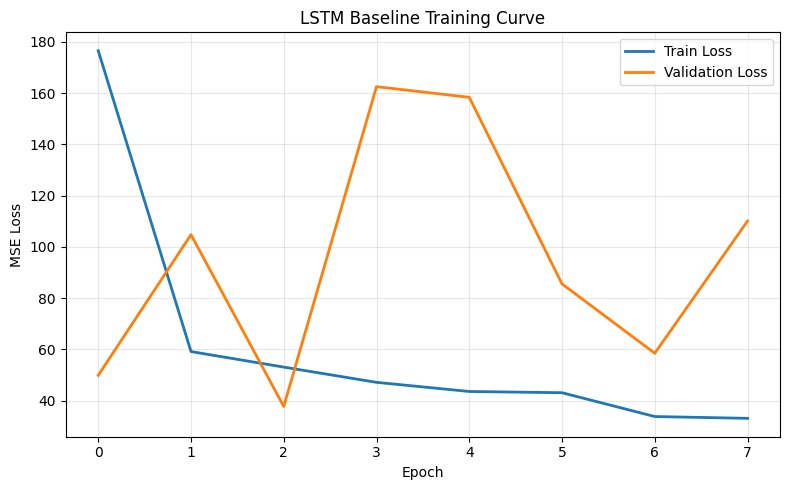

In [6]:
# ============================================================
# Training Curve
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    train_losses,
    label="Train Loss",
    linewidth=2
)

plt.plot(
    val_losses,
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "LSTM Baseline Training Curve"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "lstm_baseline_training_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [7]:
# ============================================================
# Test
# ============================================================

@torch.no_grad()
def predict(
    model,
    loader,
    device
):

    model.eval()

    predictions = []
    targets = []

    for X_batch, Y_batch in tqdm(
        loader,
        desc="Testing",
        ncols=100
    ):

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        outputs = model(
            X_batch
        )

        predictions.append(
            outputs.cpu().numpy()
        )

        targets.append(
            Y_batch.numpy()
        )

    predictions = np.concatenate(
        predictions
    ).reshape(-1)

    targets = np.concatenate(
        targets
    ).reshape(-1)

    return predictions, targets


def rmse_np(pred, true):

    return float(
        np.sqrt(
            np.mean(
                (
                    pred - true
                ) ** 2
            )
        )
    )


def mae_np(pred, true):

    return float(
        np.mean(
            np.abs(
                pred - true
            )
        )
    )


# ============================================================
# Load best checkpoint
# ============================================================

checkpoint = torch.load(
    MODEL_SAVE_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

print(
    "Best checkpoint loaded."
)

print(
    "Best Val MSE:",
    checkpoint["best_val_loss"]
)


# ============================================================
# Prediction
# ============================================================

predictions, targets = predict(
    model,
    test_loader,
    device
)


# ============================================================
# Metrics
# ============================================================

test_mse = np.mean(
    (predictions - targets) ** 2
)

test_rmse = rmse_np(
    predictions,
    targets
)

test_mae = mae_np(
    predictions,
    targets
)


print()
print("=" * 72)
print("LSTM BASELINE | TEST RESULT")
print("=" * 72)

print(
    f"Test MSE  : {test_mse:.6f}"
)

print(
    f"Test RMSE : {test_rmse:.6f}"
)

print(
    f"Test MAE  : {test_mae:.6f}"
)

print(
    f"Test N    : {len(targets):,}"
)

Best checkpoint loaded.
Best Val MSE: 37.706593294675706


Testing: 100%|██████████████████████████████████████████████████| 1225/1225 [00:30<00:00, 40.11it/s]



LSTM BASELINE | TEST RESULT
Test MSE  : 28.270447
Test RMSE : 5.316996
Test MAE  : 3.814024
Test N    : 1,253,596



PER-ENGINE RESULTS
Unit  11: RMSE=5.675630, MAE=4.339489, N=663,446
Unit  14: RMSE=7.121390, MAE=4.951074, N=156,729
Unit  15: RMSE=3.757657, MAE=2.598519, N=433,421


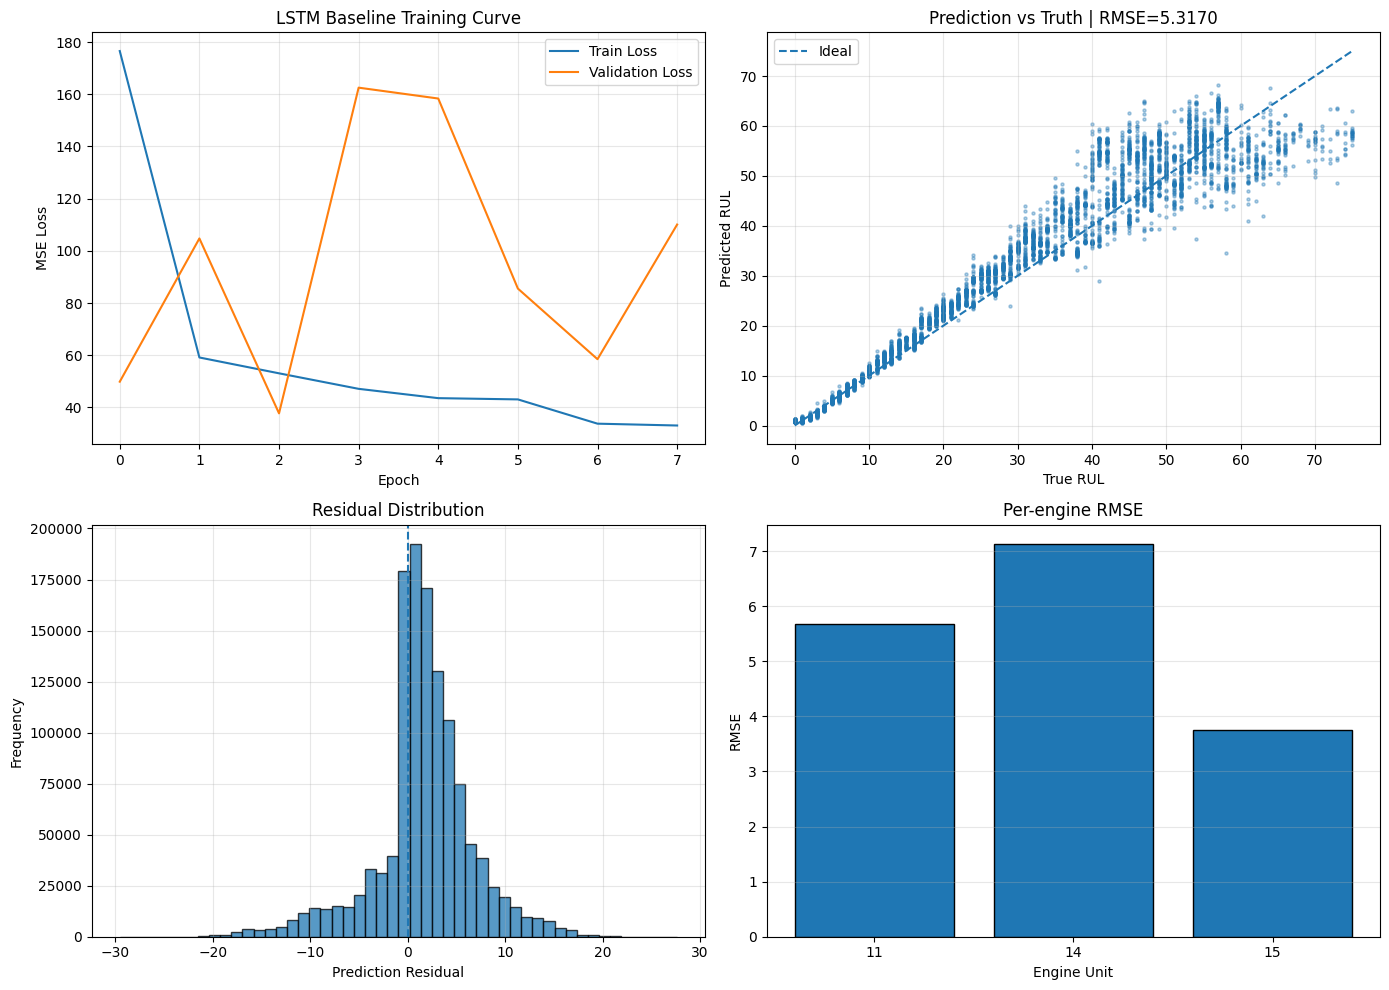


FINAL SUMMARY
Model             : lstm_baseline
Parameters        : 11,021
Best Val MSE      : 37.706593
Test MSE          : 28.270447
Test RMSE         : 5.316996
Test MAE          : 3.814024
Test windows      : 1,253,596
Checkpoint        : best_lstm_baseline.pth
Result figure     : lstm_baseline_results.png


In [8]:
# ============================================================
# Per-engine Evaluation
# ============================================================

labels = np.array([
    ut[int(start)]
    for start in test_dataset.valid_indices
])


unit_rmse = []
unit_mae = []
unit_names = []


print()
print("=" * 72)
print("PER-ENGINE RESULTS")
print("=" * 72)


for unit in np.unique(labels):

    mask = labels == unit

    unit_pred = predictions[mask]
    unit_true = targets[mask]

    r = rmse_np(
        unit_pred,
        unit_true
    )

    a = mae_np(
        unit_pred,
        unit_true
    )

    unit_rmse.append(r)
    unit_mae.append(a)
    unit_names.append(str(unit))

    print(
        f"Unit {int(unit):3d}: "
        f"RMSE={r:.6f}, "
        f"MAE={a:.6f}, "
        f"N={int(mask.sum()):,}"
    )


# ============================================================
# Visualization
# ============================================================

fig = plt.figure(
    figsize=(14, 10)
)


# ------------------------------------------------------------
# 1. Training curve
# ------------------------------------------------------------

ax = fig.add_subplot(2, 2, 1)

ax.plot(
    train_losses,
    label="Train Loss"
)

ax.plot(
    val_losses,
    label="Validation Loss"
)

ax.set_xlabel(
    "Epoch"
)

ax.set_ylabel(
    "MSE Loss"
)

ax.set_title(
    "LSTM Baseline Training Curve"
)

ax.grid(
    alpha=0.3
)

ax.legend()


# ------------------------------------------------------------
# 2. Prediction vs Truth
# ------------------------------------------------------------

ax = fig.add_subplot(2, 2, 2)

n = min(
    5000,
    len(predictions)
)

rng = np.random.default_rng(
    SEED
)

indices = rng.choice(
    len(predictions),
    size=n,
    replace=False
)

ax.scatter(
    targets[indices],
    predictions[indices],
    s=5,
    alpha=0.35
)

low = min(
    targets.min(),
    predictions.min()
)

high = max(
    targets.max(),
    predictions.max()
)

ax.plot(
    [low, high],
    [low, high],
    "--",
    label="Ideal"
)

ax.set_xlabel(
    "True RUL"
)

ax.set_ylabel(
    "Predicted RUL"
)

ax.set_title(
    f"Prediction vs Truth | "
    f"RMSE={test_rmse:.4f}"
)

ax.grid(
    alpha=0.3
)

ax.legend()


# ------------------------------------------------------------
# 3. Residual distribution
# ------------------------------------------------------------

ax = fig.add_subplot(2, 2, 3)

residuals = (
    predictions -
    targets
)

ax.hist(
    residuals,
    bins=50,
    alpha=0.75,
    edgecolor="black"
)

ax.axvline(
    0,
    linestyle="--"
)

ax.set_xlabel(
    "Prediction Residual"
)

ax.set_ylabel(
    "Frequency"
)

ax.set_title(
    "Residual Distribution"
)

ax.grid(
    alpha=0.3
)


# ------------------------------------------------------------
# 4. Per-engine RMSE
# ------------------------------------------------------------

ax = fig.add_subplot(2, 2, 4)

ax.bar(
    unit_names,
    unit_rmse,
    edgecolor="black"
)

ax.set_xlabel(
    "Engine Unit"
)

ax.set_ylabel(
    "RMSE"
)

ax.set_title(
    "Per-engine RMSE"
)

ax.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.savefig(
    RESULT_FIG_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Final Summary
# ============================================================

print()
print("=" * 72)
print("FINAL SUMMARY")
print("=" * 72)

print(
    f"Model             : {MODEL_NAME}"
)

print(
    f"Parameters        : {params:,}"
)

print(
    f"Best Val MSE      : {best_val_loss:.6f}"
)

print(
    f"Test MSE          : {test_mse:.6f}"
)

print(
    f"Test RMSE         : {test_rmse:.6f}"
)

print(
    f"Test MAE          : {test_mae:.6f}"
)

print(
    f"Test windows      : {len(test_dataset):,}"
)

print(
    f"Checkpoint        : {MODEL_SAVE_PATH}"
)

print(
    f"Result figure     : {RESULT_FIG_PATH}"
)